# VECTRA | Ingeniería de software
## Diagnóstico y propuesta Nacho · Pipeline de telemetría verificable

**Enfoque:** responsabilidades bien delimitadas, contrato de telemetría, tolerancia a reintentos y validación con un prototipo Python.

| Documento | Dato |
|---|---|
| Asignatura | Ingeniería de Software |
| Proyecto | VECTRA · Monitoreo vehicular con ESP32 y sensores |
| Entrega | Propuesta Nacho — versión mejorada |
| Rama sugerida | `feature/propuesta-Nacho` |
| Estado del proyecto | **Diseño conceptual + prototipo nuevo de referencia** |

> **Criterio de honestidad técnica:** el material recibido no contiene el firmware ni los módulos operativos de VECTRA. Los hallazgos sobre el diseño original son oportunidades de mejora documental, no defectos del código original comprobados. La sección experimental evalúa solamente el **prototipo creado para esta propuesta**, con datos sintéticos.

## 1 · Resumen ejecutivo

La propuesta Nacho transforma una secuencia conceptual de operaciones sobre telemetría en un **diseño especificado y comprobable**: recepción, validación, normalización, análisis determinista y persistencia coordinada de mediciones y alertas. La pieza central es un `TelemetryPipeline` ligero que conecta componentes pequeños mediante contratos definidos.

Los riesgos prioritarios que atiende son **entrada ambigua** (tipos, unidades y zona horaria), **lecturas repetidas por reintento**, **conflictos en identidades** y **persistencia inconsistente de alertas**. Se incluye una prueba de concepto en Python y SQLite, con pruebas reproducibles y un receptor HTTP deliberadamente restringido a *localhost*.

El objetivo **no** es presentar un sistema final, ni afirmar mejor rendimiento o mayor exactitud de detección sin mediciones de campo. Los umbrales de alerta son ilustrativos; no están entrenados ni homologados para usos de seguridad vial.

## 2 · Método y evidencia revisada

**Archivos recibidos y alcance verificable**

| Elemento | Evidencia disponible | Interpretación autorizada |
|---|---|---|
| `README.md` original | Descripción de cuatro capas: sensado, comunicación, datos/análisis, aplicación | Arquitectura **conceptual** |
| `01_analisis_y_propuesta_A.ipynb` | Propuesta A: separación de responsabilidades mediante clases especializadas | Diseño propuesto por otro integrante; se conserva intacto |
| `03_analisis_y_propuesta_Nacho.ipynb` original | Propuesta Nacho: procesamiento por etapas y diagramas Mermaid | Base de esta revisión |
| Código de sensores, servidor real o interfaz original | **No incluido** | No se pueden auditar defectos de implementación, latencias ni seguridad desplegada |
| Propuesta B | **No incluida** | No se caracteriza ni evalúa como fuente primaria |

**Método:** inventario → identificar decisiones pendientes → establecer criterios de diseño → especificar contratos → construir un prototipo de bajo costo → probar escenarios deterministas → documentar límites y trabajos restantes.

La auditoría trazable se encuentra en [`docs/AUDITORIA.md`](../docs/AUDITORIA.md).

## 3 · Arquitectura de partida documentada

![Arquitectura conceptual original](../docs/figures/01_original.png)

La cadena de cuatro capas expresa bien el propósito general de VECTRA, pero **no determina** cómo se comporta ante JSON inválido, Wi-Fi intermitente, unidades heterogéneas, mensajes duplicados, fallos de persistencia ni alertas reiteradas.

Estos son **vacíos de especificación del material revisado**, no pruebas de que el sistema actualmente falle. Antes de la etapa de desarrollo conviene resolverlos mediante contratos, casos de prueba y decisiones de recuperación.

## 4 · Matriz de riesgos y priorización

| Riesgo de diseño | Posible efecto | Severidad orientativa | Acción en la propuesta Nacho | ¿Demostrado en prototipo? |
|---|---|---|---|---|
| Mensajes sin contrato | Lecturas interpretadas de forma diferente | Alta | Esquema JSON v1 y rangos explícitos | Sí |
| Reintentos Wi-Fi | Registros y alertas duplicados | Alta | Identificador estable + deduplicación atómica | Sí |
| Identificadores reutilizados | Sobrescritura o mezcla de recorridos | Alta | Conflicto `409` y rechazo de cambios | Sí |
| Alerta separada de la transacción | Lectura aceptada con alerta faltante | Alta | Guardar lectura + alertas juntos | Sí, en SQLite |
| Exposición GPS | Riesgos de confidencialidad | Alta | API local con token; requisitos para producción | **Solo parcialmente** |
| Sensores no calibrados | Falsos positivos/negativos | Alta | Solicitar calibración y pruebas reales | No |
| Fallos prolongados de conectividad | Pérdida de lecturas en dispositivo | Alta | Diseñar cola offline y ACK por mensaje | No |
| Fragmentación excesiva | Mayor complejidad de mantenimiento | Media | Módulos por responsabilidades con flujo simple | Cualitativo |

La prioridad es **cualitativa** (alto impacto potencial). Sin datos del despliegue no corresponde asignar probabilidades numéricas ni vender estimaciones como hechos.

## 5 · Requisitos verificables y criterios de aceptación

**Funcionales mínimos:**

1. Recibir una lectura de un dispositivo y asociarla a un viaje y número de secuencia.
2. Comprobar estructura, tipos, rangos físicos plausibles, fecha con zona y unidades admitidas.
3. Convertir a UTC, g, grados, °C y km/h, preservando ubicación opcional.
4. Identificar eventos anómalos según reglas configurables de demostración.
5. Guardar cada lectura válida una sola vez; persistir alertas sin duplicarlas.
6. Distinguir explícitamente nueva lectura, repetida, inválida o conflictiva.
7. Consultar conteos, registros recientes y alertas pendientes.

**No funcionales:** rechazo sin efectos laterales para datos inválidos; módulos intercambiables; pruebas sin sensores; SQL parametrizado; documentación legible; protección básica local de la API. **Pendiente para producción:** TLS, retención de GPS, credenciales por dispositivo, cola offline, métricas, calibración y auditoría.

## 6 · Propuesta Nacho: pipeline con persistencia consistente

![Pipeline propuesto](../docs/figures/02_propuesta.png)

### ¿Por qué analizar antes de guardar?

El documento conceptual anterior sugería `almacenar → analizar → gestionar alertas`. Para el prototipo se aplica la siguiente precisión: primero se calcula el resultado **en memoria** y después se ejecuta una **única transacción SQLite** que incluye tanto la lectura como sus alertas. Así evitamos dos escrituras independientes que pueden dejar un resultado a medias.

Esto es una decisión del **prototipo**, no una modificación demostrada en el servidor original. Si en producción el análisis fuera lento, se podría migrar a eventos con *outbox* y consumidores idempotentes, evaluando el costo de coordinación. Esa arquitectura distribuida **no está implementada aquí**.

## 7 · Módulos, responsabilidades y límites

| Módulo | Responsabilidad única | Depende de | Puede probarse sin hardware |
|---|---|---|---|
| `TelemetryValidator` | Contrato y errores de entrada | Diccionario JSON | Sí |
| `TelemetryNormalizer` | Unidades, UTC y magnitud vectorial | Entrada validada | Sí |
| `RuleBasedAnomalyAnalyzer` | Reglas configurables | Registro canónico | Sí |
| `SQLiteTelemetryRepository` | Persistencia, integridad, duplicados, consultas | SQLite local | Sí |
| `TelemetryPipeline` | Coordinar sin absorber lógica especializada | Componentes inyectados | Sí |
| `http_api` | Adaptador HTTP de loopback y autenticación demo | Pipeline y token | Sí |
| `cli` | Ingesta manual, simulación, resumen | Pipeline | Sí |

**Relación con A:** la separación de responsabilidades de A es compatible con C. La aportación específica de C es el **orden de transformación**, las **entradas/salidas explícitas** y el **comportamiento frente a fallos y reintentos**. La propuesta A original se conserva sin modificar.

## 8 · Contrato de datos y semántica de reintento

El sobre `schema_version=1` contiene `device_id`, `trip_id`, `sequence`, `timestamp`, `measurements` y `gps` opcional. Se rechaza una fecha sin zona horaria y se convierten explícitamente las magnitudes conocidas.

```json
{
  "schema_version": 1,
  "device_id": "esp32_demo_01", "trip_id": "ruta_demo_01", "sequence": 1,
  "timestamp": "2026-10-15T12:01:00-06:00", "gps": {"lat": 20.5888, "lon": -100.3899},
  "measurements": {
    "acceleration": {"x": 0.1, "y": 0.01, "z": 1.0, "unit": "g"},
    "vibration": {"value": 0.25, "unit": "g"},
    "tilt": {"value": 5.0, "unit": "deg"},
    "temperature": {"value": 28.0, "unit": "C"},
    "speed": {"value": 38.0, "unit": "km/h"}
  }
}
```

**ID lógico:** `device_id:trip_id:sequence`; `received_at` no participa en la huella SHA-256. Un reenvío del mismo mensaje **no crea un segundo registro ni alerta**; si cambia su contenido se devuelve un conflicto, en vez de sobrescribir silenciosamente. El ESP32 debe preservar exactamente el JSON que reintenta.

Reglas de prueba (no umbrales validados): aceleración por eje >3 g; vibración >2 g; |inclinación| >35°; temperatura >70°C; velocidad >120 km/h. Contrato íntegro: [`docs/CONTRATO_TELEMETRIA.md`](../docs/CONTRATO_TELEMETRIA.md).

## 9 · Demostración reproducible

Las siguientes celdas importan el prototipo del repositorio, crean una base SQLite **temporal** y procesan mensajes **sintéticos**. No requieren Wi-Fi ni sensores físicos. Se recomienda abrir el notebook desde la raíz del proyecto o desde `notebooks/`.

**Las salidas de esta sección son evidencia de ejecución del prototipo, no datos capturados de vehículos.**

In [1]:
from pathlib import Path
import sys, tempfile, json
from copy import deepcopy

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "vectra").is_dir():
    raise RuntimeError("Ejecutar este notebook desde la carpeta raíz del proyecto o desde notebooks/")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from vectra.pipeline import TelemetryPipeline
from vectra.repository import SQLiteTelemetryRepository
from vectra.simulation import sample, sample_anomaly
from vectra.models import ValidationError, ConflictError

workspace = tempfile.TemporaryDirectory(prefix="vectra_c_")
repo = SQLiteTelemetryRepository(Path(workspace.name) / "telemetria.sqlite3")
pipeline = TelemetryPipeline(repo)
print("Dependencias externas requeridas: ninguna")
print("Base temporal lista; datos originales no modificados.")

Dependencias externas requeridas: ninguna
Base temporal lista; datos originales no modificados.


### 9.1 · Lectura válida, anomalía y consulta

In [2]:
r1 = pipeline.process(sample(1))
r2 = pipeline.process(sample_anomaly(2))
print("Lectura normal:", r1)
print("Lectura con eventos sintéticos:", r2)
print("Resumen:", json.dumps(repo.summary(), ensure_ascii=False))
print("Alertas pendientes:", [(a["code"], a["severity"]) for a in repo.pending_alerts()])
assert r1.status == "accepted" and r1.new_alerts == 0
assert r2.status == "accepted" and r2.new_alerts == 2

Lectura normal: IngestResult(record_id='esp32_demo_01:ruta_demo_01:1', status='accepted', new_alerts=0)
Lectura con eventos sintéticos: IngestResult(record_id='esp32_demo_01:ruta_demo_01:2', status='accepted', new_alerts=2)
Resumen: {"records": 2, "trips": 1, "devices": 1, "alerts_pending": 2}
Alertas pendientes: [('HIGH_TILT', 'warning'), ('HIGH_VIBRATION', 'warning')]


### 9.2 · Reintento idéntico frente a conflicto

Un reenvío normal después de perder la confirmación no debe duplicar alertas. Un contador reutilizado con valores diferentes debe considerarse un **conflicto**; no se modifica la lectura original.

In [3]:
retry = pipeline.process(sample_anomaly(2))
conflicting = sample_anomaly(2)
conflicting["measurements"]["speed"]["value"] = 99.0
try:
    pipeline.process(conflicting)
except ConflictError as exc:
    conflict_message = str(exc)
else:
    raise AssertionError("Se esperaba detectar identidad repetida con contenido diferente")

print("Reenvío:", retry.status, "| alertas nuevas:", retry.new_alerts)
print("Conflicto detectado:", conflict_message)
print("Registros:", repo.summary()["records"], "| alertas:", repo.summary()["alerts_pending"])
assert retry.status == "duplicate" and retry.new_alerts == 0
assert repo.summary()["records"] == 2 and repo.summary()["alerts_pending"] == 2

Reenvío: duplicate | alertas nuevas: 0
Conflicto detectado: Registro conflictivo: identificador repetido con distinta telemetría
Registros: 2 | alertas: 2


### 9.3 · Validación de errores y normalización de unidades

In [4]:
invalid = sample(3)
invalid["measurements"]["speed"]["unit"] = "nudos"
try:
    pipeline.process(invalid)
except ValidationError as exc:
    print("Entrada rechazada correctamente:", exc)
else:
    raise AssertionError("No se rechazó unidad desconocida")

converted = sample(4)
converted["measurements"]["speed"] = {"value": 10.0, "unit": "m/s"}
converted["measurements"]["temperature"] = {"value": 98.6, "unit": "F"}
converted["gps"] = None  # pérdida de fix GPS: no inventar coordenadas
pipeline.process(converted)
last = next(x for x in repo.recent(10) if x["sequence"] == 4)
print("Velocidad en km/h:", last["speed_kmh"])
print("Temperatura en °C:", round(last["temperature_c"], 2))
print("Hora original normalizada a UTC:", last["measured_at"])
print("GPS no disponible:", last["latitude"] is None)
assert abs(last["speed_kmh"] - 36) < 1e-9
assert abs(last["temperature_c"] - 37) < 1e-9

Entrada rechazada correctamente: speed: unidad no admitida; use km/h, m/s
Velocidad en km/h: 36.0
Temperatura en °C: 37.0
Hora original normalizada a UTC: 2026-10-15T18:04:00.000000Z
GPS no disponible: True


### 9.4 · Representación de ejemplo: resultados de reglas

Esta gráfica resume los eventos que generó **una única lectura sintética**. No es una medición de desempeño ni una evaluación de tasas de detección.

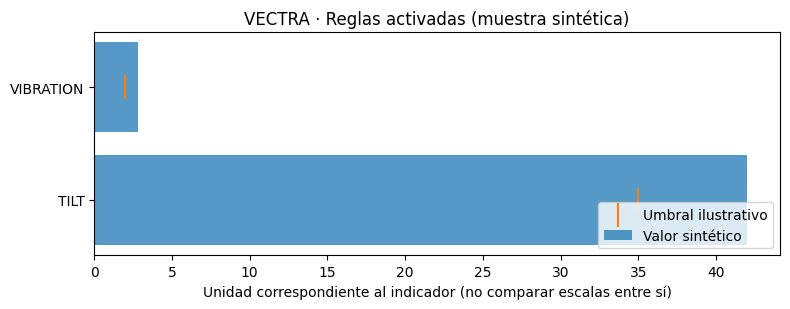

In [5]:
# Gráfico opcional: Matplotlib suele venir instalado en entornos científicos.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Matplotlib no está instalado; el pipeline funciona sin él.")
else:
    alerts = [a for a in repo.pending_alerts() if a["record_id"].endswith(":2")]
    names = [a["code"].replace("HIGH_", "") for a in alerts]
    values = [a["value"] for a in alerts]
    limits = [a["threshold"] for a in alerts]
    positions = list(range(len(alerts)))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh(positions, values, alpha=0.75, label="Valor sintético")
    ax.scatter(limits, positions, marker="|", s=280, label="Umbral ilustrativo")
    ax.set_yticks(positions, names)
    ax.set_xlabel("Unidad correspondiente al indicador (no comparar escalas entre sí)")
    ax.set_title("VECTRA · Reglas activadas (muestra sintética)")
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

## 10 · Pruebas automatizadas

Se ejecuta la batería `unittest` incluida en `tests/`. Revisa al menos: aceptación, duplicados, conflictos, UTC, conversión de unidades, GPS opcional, rangos, JSON estricto, reglas inyectables, reordenación por offline, autenticación y errores HTTP. Son **pruebas del prototipo**, no pruebas de integración con firmware real.

In [6]:
import subprocess
result = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    cwd=PROJECT_ROOT, capture_output=True, text=True, timeout=120,
)
print("Código de salida:", result.returncode)
print("\n".join(result.stderr.strip().splitlines()[-5:]))
if result.returncode != 0:
    print(result.stderr[-5000:])
assert result.returncode == 0, "Alguna prueba del prototipo falló"

Código de salida: 0

----------------------------------------------------------------------
Ran 26 tests in 2.844s

OK


### 10.1 · Consola visual local (extensión del prototipo)

El servidor HTTP de demostración también ofrece un pequeño dashboard en **`http://127.0.0.1:8081/`**: conteos, gráfica de velocidad de muestras sintéticas, últimas lecturas y alertas **pendientes de entrega**. Su interfaz es autocontenida y no requiere frameworks ni CDN.

Para usarlo: primero corre `python -m vectra.cli --db data/vectra.sqlite3 demo`, define `VECTRA_API_TOKEN` y lanza `python -m vectra.cli --db data/vectra.sqlite3 serve --port 8081`. Introduce el token en el navegador. El acceso sigue restringido a **localhost**; no es una plataforma de vigilancia real ni sustituye una pasarela segura para ESP32.

## 11 · Decisiones de ingeniería y compromisos

| Decisión | Ventaja | Coste o limitación |
|---|---|---|
| Python estándar / SQLite | Demostración sin dependencias externas | No escala horizontal ni ofrece migraciones |
| JSON v1 estricto | Errores claros, unidades explícitas | Nuevos campos requieren versionado |
| Hash del registro normalizado | Distingue duplicado y conflicto | Punto flotante puede variar; reintentar mismo JSON |
| Detección antes de transacción | Lectura+alertas atómicas | La ingesta se bloquea durante el análisis |
| Reglas simples sin ML | Resultados trazables en pruebas | Sin sensibilidad/especificidad demostrada |
| API HTTP solo `127.0.0.1` | Evaluación aislada y acotada | No recibe tráfico del ESP32 real |
| GPS nulo cuando no hay fijación | No inventa coordenadas | Hay lecturas sin mapa |

**Sobre seguridad:** el token estático es adecuado únicamente para una demo local. Una solución desplegada necesita TLS, autenticación individual, autorización para GPS, rotación de credenciales, controles de tasa, registros de seguridad y política de retención. No basta con abrir el puerto 8081 a la red.

## 12 · Métricas y plan de validación posterior

No se cuenta con mediciones de dispositivos reales ni con observaciones de un despliegue operativo. Por ello, las siguientes **métricas por medir** se proponen como criterios de validación y no se publican valores inventados:

| Dimensión | Indicador propuesto | Método |
|---|---|---|
| Ingesta | Latencia p50/p95/p99, registros/s | Prueba con carga realista y límites definidos |
| Integridad | Registros perdidos, duplicados, conflictos | Ensayos de caída Wi-Fi/reinicio e IDs de extremo a extremo |
| Sensores | Ruido RMS, desviación, sesgo y calibración | Comparación con instrumentos de referencia |
| Analizador | Precision, recall, falsos positivos por recorrido | Casos etiquetados y validación cruzada |
| GPS | Porcentaje de fix válido, error de ubicación | Muestreo en rutas conocidas |
| Seguridad | Resultados de revisión de amenazas | Pruebas de autenticación, privacidad, TLS y permisos |
| Operación | Ocupación de cola, fallos, recuperación | Inyección de fallos y telemetría interna |

Cualquier objetivo cuantitativo deberá acordarse con el equipo tras conocer frecuencia de muestreo, transporte, volumen de dispositivos y criticidad del uso.

## 13 · Plan incremental de implementación

| Fase | Prioridad | Entregable | Verificación de cierre |
|---|---|---|---|
| P0 · Contrato y modelo | Alta | Esquema v1 y flujo básico | Mensajes correctos/incorrectos clasificados |
| P0 · Consistencia | Alta | Identidad estable y persistencia atómica | Reenvío sin duplicados ni alerta parcial |
| P0 · Sensores | Alta | Driver MPU6050, GPS y temperatura con calibración | Trazas físicas contrastadas |
| P1 · Conectividad | Alta | Gateway HTTPS y cola persistente con ACK | Cortes y reinicios sin pérdida silenciosa |
| P1 · Acceso | Alta | Identidades de dispositivos, roles, retención de GPS | Evaluación de amenaza documentada |
| P1 · Producto | Media | Consultas autenticadas y dashboard | Pruebas de usabilidad / historial coherente |
| P2 · Analítica | Media | Algoritmos ajustados con datos reales | Métricas de detección y revisión de sesgos |
| P2 · Escalado | Según necesidad | Base de datos, colas y métricas productivas | SLO y costos validados |

Las primeras dos fases cuentan con un **prototipo verificable** en esta entrega. Las demás están pendientes y no deben describirse como terminadas.

## 14 · Conclusión

El análisis permitió distinguir dos niveles que en una propuesta de software suelen confundirse: **la arquitectura que se dibuja** y **las garantías que pueden comprobarse**. Las cuatro capas de VECTRA ofrecen una visión útil del sistema, pero por sí solas no explican qué hacer ante una unidad desconocida, una fecha sin zona, una interrupción de Wi-Fi o un mensaje reenviado.

La propuesta Nacho introduce responsabilidades explícitas y un contrato v1 que reduce interpretaciones ambiguas. En el prototipo se comprobaron validaciones, conversiones de unidades, almacenamiento transaccional, control de duplicados y pruebas HTTP locales. También quedó claro lo que todavía falta: hardware real, cola offline, seguridad de red, calibración, dashboard de producto y evaluación de detección.

El principal resultado no es añadir más clases, sino **poder demostrar qué garantiza cada etapa, dónde falla y qué trabajo queda pendiente**. Esto permite que VECTRA evolucione sin atribuir a una maqueta académica capacidades que aún no ha demostrado.

**Fuentes internas:** `README.md`, `docs/AUDITORIA.md`, `docs/ARQUITECTURA.md`, `docs/CONTRATO_TELEMETRIA.md` y `docs/ESP32_E_INTEGRACION.md`.

In [7]:
workspace.cleanup()
print("Directorio temporal de la demostración cerrado.")

Directorio temporal de la demostración cerrado.
